# ECS708P Coursework 1 — Interim Submission
## Representation & Latent Structure of Fashion-MNIST

**Author:** Suryanshu Anand

This notebook covers the interim deliverable: learning and evaluating compact linear representations (PCA) of
Fashion-MNIST, and comparing a linear (PCA) and a non-linear (t-SNE) 2D view of the data. It answers:

1. How many principal components are needed to capture **90%** and **95%** of the variance?
2. How does **reconstruction MSE** change with latent dimension *k*?
3. Do **2D projections** reveal natural class separation or overlap?
4. What is the **intrinsic dimensionality** of the data?

All analysis code lives in the repository's `src/` package; this notebook calls it so the notebook and the
command-line runner (`python -m experiments.run_representation --seed 42 --save_dir outputs/`) produce identical
figures and metrics. See `README.md` for setup and reproduction instructions.

## 1. Setup and reproducibility

- Every stochastic step receives `seed = 42` (data split, subsampling, t-SNE).
- **No data leakage:** PCA is fitted on the training split only; validation images are only ever *transformed*.
  The official test split is not used anywhere in this notebook — it is reserved for a single final evaluation.
- Figures are saved to `outputs/figures/` at 300 DPI; metrics to `outputs/metrics/`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from experiments.run_representation import (
    MSE_KS, RECON_SAMPLE_CLASSES, TSNE_PCA_DIM, TSNE_PERPLEXITY, VIS_SAMPLE_SIZE,
    build_interim_metrics, plot_explained_variance, plot_manifold_comparison, plot_reconstruction_mse,
    plot_reconstructions,
)
from src.data_loader import CLASS_NAMES, load_splits
from src.evaluate import apply_style, knn_accuracy, save_figure, save_json
from src.representation import (
    components_for_variance, embed_2d, fit_pca, mle_intrinsic_dimension, project, reconstruction_mse,
)
from src.utils import FIGURES_DIR, METRICS_DIR, ROOT, set_seed

SEED = 42
set_seed(SEED)
apply_style()
pd.set_option("display.precision", 4)


def show_and_save(fig, name: str) -> None:
    """Display a figure inline, then save it to outputs/figures/ at 300 DPI."""
    display(fig)
    path = save_figure(fig, name, FIGURES_DIR)
    print(f"Saved {path.relative_to(ROOT)}")

## 2. Data

Fashion-MNIST: 70,000 grayscale 28×28 images of 10 clothing classes. The official 60,000-image training set is split
(stratified, `seed = 42`) into **50,000 train / 10,000 validation**; the official 10,000-image **test** set is held
out untouched. Files are downloaded on first use and verified against their published MD5 checksums. Pixels are
scaled to [0, 1] by the constant 1/255 (nothing is fitted).

In [2]:
splits = load_splits(seed=SEED)
X_train, y_train, X_val, y_val = splits.X_train, splits.y_train, splits.X_val, splits.y_val

display(pd.DataFrame({
    "split": ["train", "validation", "test (held out)"],
    "images": [len(X_train), len(X_val), len(splits.X_test)],
    "features": [X_train.shape[1], X_val.shape[1], splits.X_test.shape[1]],
    "images per class": [np.bincount(y).tolist()[0] for y in (y_train, y_val, splits.y_test)],
}))

,split,images,features,images per class
0,train,50000,784,5000
1,validation,10000,784,1000
2,test (held out),10000,784,1000


## 3. PCA: how many components capture 90% and 95% of the variance?

PCA is fitted on the 50,000 training images. Because every pixel shares the same unit and range, the data is
**centred but not standardised** — standardising would inflate noise in the near-constant border pixels.

In [3]:
pca = fit_pca(X_train, seed=SEED)
assert np.allclose(pca.mean_, X_train.mean(axis=0)), "PCA statistics must come from the training split only"

ratios = pca.explained_variance_ratio_
cumulative = np.cumsum(ratios)
k_for = components_for_variance(pca, (0.90, 0.95, 0.99))
k90, k95 = k_for[0.90], k_for[0.95]

display(pd.DataFrame({
    "variance threshold": [f"{t:.0%}" for t in k_for],
    "components needed (k)": list(k_for.values()),
    "exact cumulative variance": [cumulative[k - 1] for k in k_for.values()],
    "fraction of 784 dims": [k / X_train.shape[1] for k in k_for.values()],
}))
print(f"PC1 explains {ratios[0]:.1%} and PC2 {ratios[1]:.1%} of the variance.")

,variance threshold,components needed (k),exact cumulative variance,fraction of 784 dims
0,90%,84,0.9006,0.1071
1,95%,187,0.9500,0.2385
2,99%,459,0.9901,0.5855


PC1 explains 29.0% and PC2 17.8% of the variance.


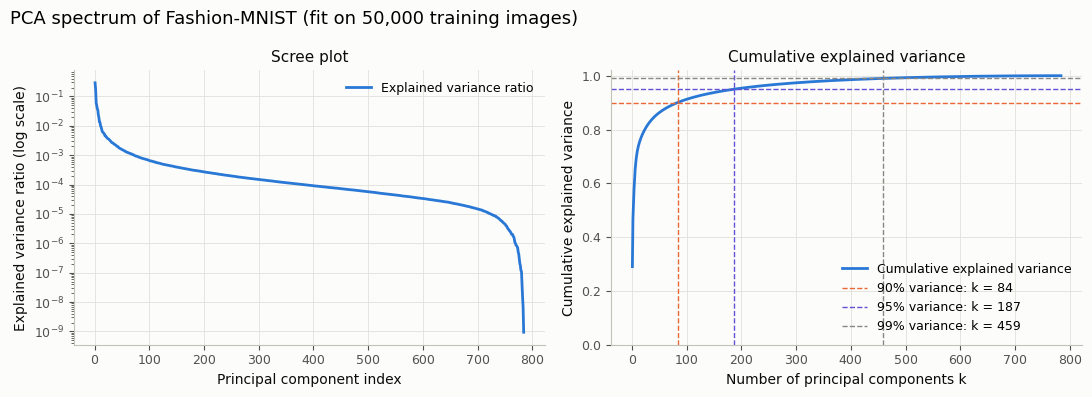

Saved outputs/figures/pca_explained_variance.png


In [4]:
show_and_save(plot_explained_variance(cumulative, ratios, k_for), "pca_explained_variance.png")

**Interpretation.** Variance is highly concentrated: two components already explain almost half of it, and
**84 components (≈11% of the 784 pixels) capture 90%** and **187 (≈24%) capture 95%**. The scree plot decays
smoothly with no sharp elbow, so there is no single "natural" cut-off: each extra 5% of variance costs
progressively more components (84 → 187 → 459 for 90 → 95 → 99%). The last 100 components together explain
only 0.08% of the variance, reflecting near-constant border pixels.

## 4. Reconstruction error as the latent dimension *k* varies

Each image is projected onto the first *k* components and mapped back to pixel space; the error is the mean squared
per-pixel difference. Comparing **train** and **validation** error checks whether the learned basis generalises to
images PCA never saw.

In [5]:
mse_ks = sorted(set(MSE_KS) | {2, 10, 50, 100, 200} | set(k_for.values()))
mse_df = pd.DataFrame({
    "k": mse_ks,
    "cumulative_explained_variance": [float(cumulative[k - 1]) for k in mse_ks],
    "mse_train": reconstruction_mse(pca, X_train, mse_ks),
    "mse_val": reconstruction_mse(pca, X_val, mse_ks),
})

interim_table = mse_df[mse_df["k"].isin(sorted({2, 10, 50, 100, 200, k90, k95}))].reset_index(drop=True)
interim_table["val / train"] = interim_table["mse_val"] / interim_table["mse_train"]
display(interim_table)

,k,cumulative_explained_variance,mse_train,mse_val,val / train
0,2,0.4679,0.0463,0.0462,0.9967
1,10,0.7199,0.0244,0.0243,0.9980
2,50,0.8626,0.0120,0.0119,0.9968
3,84,0.9006,0.0087,0.0086,0.9967
4,100,0.9123,0.0076,0.0076,0.9971
5,187,0.9500,0.0044,0.0044,1.0060
6,200,0.9537,0.0040,0.0041,1.0068


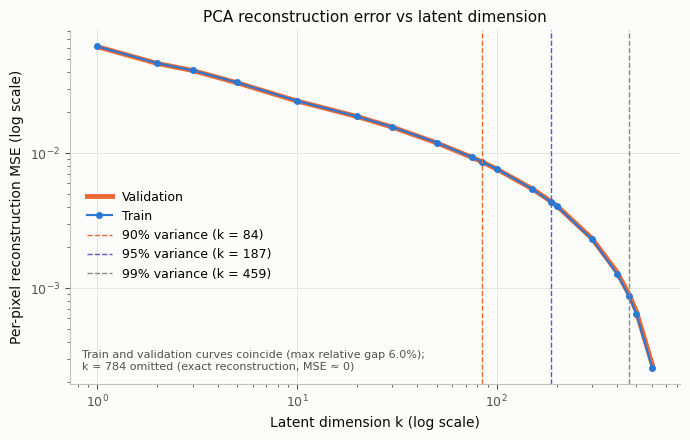

Saved outputs/figures/reconstruction_mse_vs_k.png


In [6]:
show_and_save(plot_reconstruction_mse(mse_df, k_for), "reconstruction_mse_vs_k.png")

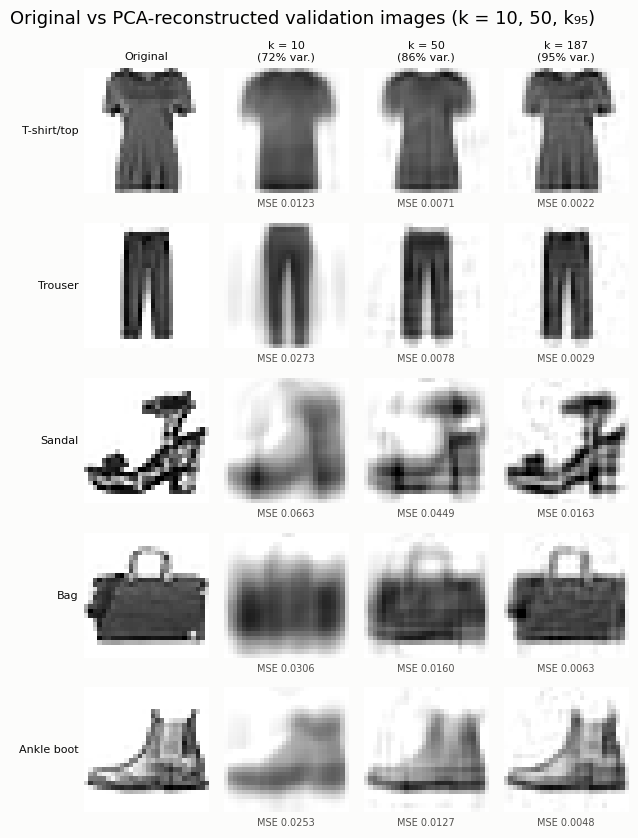

Saved outputs/figures/reconstruction_samples.png


In [7]:
show_and_save(
    plot_reconstructions(
        pca, X_val, y_val, [10, 50, k95], cumulative, classes=RECON_SAMPLE_CLASSES, show_mse=True,
        title="Original vs PCA-reconstructed validation images (k = 10, 50, k₉₅)",
    ),
    "reconstruction_samples.png",
)

**Interpretation.**

- MSE falls monotonically with *k* — from ≈0.046 at *k* = 2 to ≈0.0087 at *k*₉₀ = 84 and ≈0.0044 at *k*₉₅ = 187 —
  each doubling of *k* removes roughly a quarter to a half of the remaining error (×0.77 from 10→20, ×0.53 from
  100→200), and the decline accelerates beyond *k* ≈ 200.
- **Validation MSE matches training MSE** at every *k* (ratio ≈ 1.00), so the principal subspace learned from the
  training split generalises: PCA is not overfitting.
- The samples show *what* each component budget buys: at *k* = 10 only the coarse silhouette survives (garment type is
  recognisable, texture is not); by *k* = 50 shape boundaries such as the bag handle and trouser gap appear; at
  *k* = 187 fine texture returns. Error is strongly **class-dependent** — sandals, with thin straps and high-contrast
  detail, have the largest error at every *k*, while smooth, uniform trousers and T-shirts reconstruct best.

## 5. Do 2D projections reveal class structure? PCA vs t-SNE

Both embeddings use the **same 5,000 training images** (500 per class, stratified, `seed = 42`). t-SNE
(perplexity 30) is run on the first 50 principal components to suppress pixel noise. t-SNE is transductive, so it is
used **for visualisation only** — never as model features.

Subsample: 5,000 images, per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


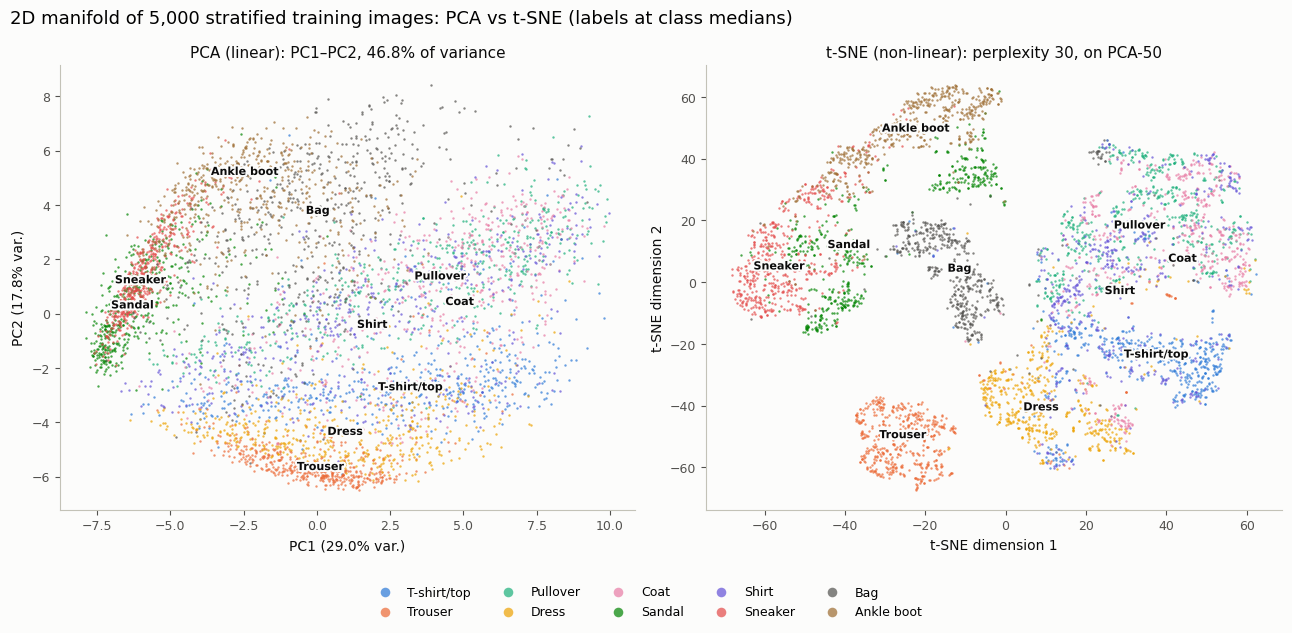

Saved outputs/figures/manifold_2d_pca_vs_tsne.png


In [8]:
vis_idx, Z_pca, Z_tsne = embed_2d(
    pca, X_train, y_train, n_samples=VIS_SAMPLE_SIZE, perplexity=TSNE_PERPLEXITY, tsne_pca_dim=TSNE_PCA_DIM, seed=SEED,
)
print(f"Subsample: {len(vis_idx):,} images, per class: {np.bincount(y_train[vis_idx]).tolist()}")
show_and_save(
    plot_manifold_comparison(Z_pca, Z_tsne, y_train[vis_idx], ratios, TSNE_PERPLEXITY),
    "manifold_2d_pca_vs_tsne.png",
)

**Interpretation.**

- **PCA (linear, 46.8% of variance in 2D)** recovers only the coarse *super-categories*: footwear (Sneaker, Sandal,
  Ankle boot) on the left, Trouser and Dress along the bottom, Bag at the top, and upper-body garments in the centre.
  Classes within each group overlap heavily — PC1 largely encodes "how much of the frame is filled", PC2
  "tall/narrow vs wide" shapes.
- **t-SNE (non-linear)** separates much more: Trouser, Bag, Sneaker, Sandal and Ankle boot form compact,
  well-separated clusters, and Dress is mostly distinct.
- **Persistent overlap:** even under t-SNE, **Shirt, Pullover and Coat** (and partly T-shirt/top) remain intermixed.
  These garments share the same silhouette and differ mainly in fine details (collars, buttons, sleeves), which
  pixel-level similarity does not capture. This predicts where supervised classifiers will make most of their errors.
- That t-SNE separates far more than PCA indicates that class structure lies on a **non-linear manifold** that a 2D
  linear projection cannot unfold.

## 6. Additional evidence: intrinsic dimensionality and separability vs *k*

Variance thresholds measure *linear* dimensionality. As a complementary non-linear estimate, the Levina–Bickel
maximum-likelihood estimator uses nearest-neighbour distance ratios (5,000-image subsample, `seed = 42`). To quantify
class separation beyond the plots, a 5-nearest-neighbour classifier is **fitted on train embeddings and scored on
validation** in PCA spaces of increasing *k*.

In [9]:
mle = {n: mle_intrinsic_dimension(X_train, n_neighbors=n, seed=SEED) for n in (10, 20)}
display(pd.DataFrame({"neighbours used": list(mle), "MLE intrinsic dimension": list(mle.values())}))

rows = []
for k in (2, 3, 10, 50, k90, k95):
    rows.append({"space": f"PCA-{k}", "5-NN validation accuracy":
                 knn_accuracy(project(pca, X_train, k), y_train, project(pca, X_val, k), y_val)})
rows.append({"space": "raw pixels (784)", "5-NN validation accuracy": knn_accuracy(X_train, y_train, X_val, y_val)})
display(pd.DataFrame(rows))

,neighbours used,MLE intrinsic dimension
0,10,12.6681
1,20,11.7662


,space,5-NN validation accuracy
0,PCA-2,0.5227
1,PCA-3,0.6368
2,PCA-10,0.8180
3,PCA-50,0.8647
4,PCA-84,0.8678
5,PCA-187,0.8690
6,raw pixels (784),0.8595


**Interpretation.**

- The non-linear estimate (**≈12 dimensions**) is far below the 84 linear components needed for 90% variance: the
  images lie near a low-dimensional *curved* manifold that PCA needs many flat directions to approximate.
- Class separability grows steeply with *k* (2D ≈ 52%, 3D ≈ 64%, 10D ≈ 82% 5-NN accuracy) and saturates around
  50–100 components, where it slightly **exceeds raw pixels** — the discarded low-variance components are mostly
  noise. 2D/3D views are therefore useful for intuition but discard most class-discriminative information.

## 7. Save interim metrics

In [10]:
interim = build_interim_metrics(SEED, X_train.shape, k_for, cumulative, mse_df)
path = save_json(interim, "representation_interim.json", METRICS_DIR)
print(f"Saved {path.relative_to(ROOT)}")
display(pd.DataFrame(interim["reconstruction_mse"]))

Saved outputs/metrics/representation_interim.json


,k,cumulative_explained_variance,mse_train,mse_val
0,2,0.4679,0.0463,0.0462
1,10,0.7199,0.0244,0.0243
2,50,0.8626,0.0120,0.0119
3,84,0.9006,0.0087,0.0086
4,100,0.9123,0.0076,0.0076
5,187,0.9500,0.0044,0.0044
6,200,0.9537,0.0040,0.0041


## 8. Summary

| Question | Answer (train-fitted PCA, validated on held-out validation split) |
|---|---|
| Components for 90% / 95% variance | **84 / 187** of 784 (99% needs 459) |
| Reconstruction MSE vs *k* | 0.046 (*k*=2) → 0.024 (10) → 0.012 (50) → 0.0087 (84) → 0.0044 (187); train ≈ validation, so PCA generalises |
| 2D class separation | PCA separates only super-categories; t-SNE isolates Trouser, Bag and footwear, but Shirt/Pullover/Coat/T-shirt overlap in both |
| Intrinsic dimensionality | ≈12 (non-linear MLE) vs 84–187 (linear PCA) — a curved low-dimensional manifold |

**Next steps (final submission):** clustering on raw vs PCA spaces (K-Means/GMM, *k* ∈ [2, 15], ARI/NMI/purity),
then linear vs non-linear classifiers across representation dimensions, learning curves, and a single held-out test
evaluation.